# Create a Bathymetry Surface using Landsat and ICESat-2 data

*Section 10 — Case study: ICESat-2 bathymetry, notebook 3 of 5.* Previous: `02_landsat_composites`. Next: `04_landsat_scenes_bathymetry`.

**You will learn:**
- how to merge, split (train/test) and sample point data with image values (`rsgispy.vector`, `rsgispy.zonalstats.point`);
- how to fit a random forests regression of depth against reflectance and assess feature importance (`rsgispy.tools.plotting.plot_feature_importance_bars`);
- how to apply the model to an image within a mask (`rsgispy.regression.regsklearn.apply_sklearn_regressor`);
- how to assess the result with independent test points: accuracy metrics, predicted v observed, residual and QQ plots (`rsgispy.regression.regmetrics`).

**Before you start:** run `02_landsat_composites` of this section (it creates the composite used here). Regression is introduced in section 5 (`05_regression`).

**Data:** `../data/is2_bathy/is2_bermuda_depth.gpkg`, `../data/is2_bathy/bermuda_land_area.geojson`, `../data/is2_bathy/bermuda_valid_water_mask.geojson` and `outputs/ls_comp/bermuda_max_ndvi_ndwi_landsat_comp.tif` (from notebook 02).

**Run time:** about 1 minute.

In this notebook you will use the ICESat-2 data we looked at in the first notebook and the Landsat composite created in the second to define a bathymetry surface of the whole region.

This analysis is based on a key assumption which defines the scope of what is possible. That assumption is that optical reflectance (i.e., from Landsat or Sentinel-2 etc.) varies with water depth with some reflectance coming from the seabed. Clearly this only holds to a certain depth and will also be dependent on the water conditions at the time of the acquisition, for example, river mouths can be sensitive to storms where increases in the amount of sediment in the water can reduce the ability to see through the water column. This is also relevant for the ICESat-2 data which has a wavelength of 532 nm. Additionally, the assumption is that reflectance will be dependent on water depth and there are other factors which could be impacting on the reflectance, for example different seabed materials or geologies might cause the reflectance to be different.

Given these assumptions we can therefore only apply this analysis to regions of relatively shallow water, up to the maximum depth of the ICESat-2 measurements and where the water is clear.

# 1. Imports

In [1]:
import os

import geopandas
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.masking
import rsgispy.imageutils.metadata
import rsgispy.imageutils.rasterise
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster
import rsgispy.regression.regmetrics
import rsgispy.regression.regsklearn
import rsgispy.tools.plotting
import rsgispy.vector.io
import rsgispy.vector.selection
import rsgispy.zonalstats.point
from rsgispy.imageutils.masking import ImageBandInfo

# Import Random Forests RandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

# 2. Define Input Datasets

In [2]:
# The original ICESat-2 data.
is2_vec_file = "../data/is2_bathy/is2_bermuda_depth.gpkg"

# The Landsat Composite created in the second notebook
landsat_comp_img = "outputs/ls_comp/bermuda_max_ndvi_ndwi_landsat_comp.tif"

# The land area vector layer for defining the valid area
land_area_vec_file = "../data/is2_bathy/bermuda_land_area.geojson"
land_area_vec_lyr = "bermuda_land_area"

# The ocean water area vector layer
ocean_area_vec_file = "../data/is2_bathy/bermuda_valid_water_mask.geojson"
ocean_area_vec_lyr = "bermuda_valid_water_mask"

out_dir = "outputs/ls_comp_bathy"
os.makedirs(out_dir, exist_ok=True)

# 3. Merge ICESat-2 Paths

The ICESat-2 data has been provided to you as a multi-layer vector file. For this analysis we want just a single vector layer so we do not have to repeat processing steps for the different layers. The following command merges the vector layers into a single layer.

In [3]:
is2_all_vec_file = os.path.join(out_dir, "is2_bermuda_depth_sgl_lyr_all.gpkg")
is2_all_vec_lyr = "is2_bermuda_depth_sgl_lyr_all"
# Remove the output if it already exists (e.g., the notebook is re-run).
if os.path.exists(is2_all_vec_file):
    rsgispy.vector.io.delete_vec_file(is2_all_vec_file)
rsgispy.vector.io.merge_vec_file_lyrs(
    is2_vec_file, out_vec_file=is2_all_vec_file, out_vec_lyr=is2_all_vec_lyr
)
print(rsgispy.vector.io.get_vec_feat_count(is2_all_vec_file, is2_all_vec_lyr))

  0%|          | 0/1 [00:00<?, ?it/s]

37026


# 4. Extract Random Sample of ICESat-2 Returns

This step will extract a random 20 % sample of all the ICESat-2 returns and these will be used to validate the final bathymetry surfaces. Given the large number of returns in the ICESat-2 data, taking a sample to use as a validation dataset is a good idea as while k-fold and bootstrapping can be used to derive statistics on the model accuracy it is ideal to have an independent dataset.

In [4]:
is2_train_vec_file = os.path.join(out_dir, "is2_bermuda_depth_train.gpkg")
is2_train_vec_lyr = "is2_bermuda_depth_train"
is2_test_vec_file = os.path.join(out_dir, "is2_bermuda_depth_test.gpkg")
is2_test_vec_lyr = "is2_bermuda_depth_test"

rsgispy.vector.selection.create_train_test_smpls(
    is2_all_vec_file,
    is2_all_vec_lyr,
    is2_train_vec_file,
    is2_train_vec_lyr,
    is2_test_vec_file,
    is2_test_vec_lyr,
    out_format="GPKG",
    prop_test=0.2,
    rnd_seed=42,
    del_exist_vec=True,
)
print(f"Number of Training Features: {rsgispy.vector.io.get_vec_feat_count(is2_train_vec_file, is2_train_vec_lyr)}")
print(f"Number of Testing Features: {rsgispy.vector.io.get_vec_feat_count(is2_test_vec_file, is2_test_vec_lyr)}")

Number of Training Features: 29621
Number of Testing Features: 7405


# 5. Check the Data Projections.

A common error which can occur when combining datasets from different sources is that they are in different projections.

The code cells below show two ways you can check the projections. The first gets the WKT string and prints them out and then you can manually check they look the same.

In [5]:
is2_wkt = rsgispy.vector.io.get_wkt_proj_from_vec(
    is2_vec_file, vec_lyr="ic2_depth_bermuda_path1"
)

ls_img_wkt = rsgispy.imageutils.metadata.get_wkt_proj_from_img(landsat_comp_img)

print(is2_wkt)
print(ls_img_wkt)

PROJCRS["WGS 84 / UTM zone 20N",BASEGEOGCRS["WGS 84",ENSEMBLE["World Geodetic System 1984 ensemble",MEMBER["World Geodetic System 1984 (Transit)"],MEMBER["World Geodetic System 1984 (G730)"],MEMBER["World Geodetic System 1984 (G873)"],MEMBER["World Geodetic System 1984 (G1150)"],MEMBER["World Geodetic System 1984 (G1674)"],MEMBER["World Geodetic System 1984 (G1762)"],MEMBER["World Geodetic System 1984 (G2139)"],MEMBER["World Geodetic System 1984 (G2296)"],ELLIPSOID["WGS 84",6378137,298.257223563,LENGTHUNIT["metre",1]],ENSEMBLEACCURACY[2.0]],PRIMEM["Greenwich",0,ANGLEUNIT["degree",0.0174532925199433]],ID["EPSG",4326]],CONVERSION["UTM zone 20N",METHOD["Transverse Mercator",ID["EPSG",9807]],PARAMETER["Latitude of natural origin",0,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8801]],PARAMETER["Longitude of natural origin",-63,ANGLEUNIT["degree",0.0174532925199433],ID["EPSG",8802]],PARAMETER["Scale factor at natural origin",0.9996,SCALEUNIT["unity",1],ID["EPSG",8805]],PARAMETER["False e

An alternative method is to compare the EPSG codes which is much easier to automate with a simple if statement:

In [6]:
is2_epsg = rsgispy.vector.io.get_epsg_proj_from_vec(
    is2_vec_file, vec_lyr="ic2_depth_bermuda_path1"
)
ls_img_epsg = rsgispy.imageutils.metadata.get_epsg_proj_from_img(landsat_comp_img)

print(f"ICESat-2 EPSG: {is2_epsg}")
print(f"Landsat EPSG: {ls_img_epsg}")

if is2_epsg == ls_img_epsg:
    print("Datasets have matching projections")
else:
    print("Projections DO NOT match - you probably need to sort something out here...")

ICESat-2 EPSG: 32620
Landsat EPSG: 32620
Datasets have matching projections


Good news, the projections match so we can move on. If they did not match then you would need to reproject one of the datasets, in this case I would reproject the vector layer (i.e., the ICESat-2) as there is less error associated with reprojecting vector layers compared to raster layers which need to be resampled.

# 6. Extract the Landsat Reflectance at the Points

Note, for this analysis we will just use the visual bands (i.e., Coastal, Blue, Green, Red) for the analysis as the NIR and SWIR bands are largely absorbed by water.

The valid ranges of values would normally be 0 (i.e., no reflectance) to 10,000 (i.e., 100 % reflectance) but for low values of reflectance it can be possible (as in this case) that the atmospheric correction has provided a physically impossible negative reflectance value. Pixel values outside of the range -100 to 10,000 will be assigned the value -9999 and removed from the dataset.

`ext_point_band_values_file` can extract several bands in one call, writing one column per band (named by `out_field`). The file is updated in place.

In [7]:
rsgispy.zonalstats.point.ext_point_band_values_file(
    is2_train_vec_file,
    is2_train_vec_lyr,
    landsat_comp_img,
    img_band=[1, 2, 3, 4],
    min_thres=-100,
    max_thres=10000,
    out_no_data_val=-9999,
    out_field=["ls_coastal", "ls_blue", "ls_green", "ls_red"],
)

  0%|          | 0/29621 [00:00<?, ?it/s]

# 7. Remove Invalid Values From Datasets

In the next step we will remove points which do not have valid Landsat reflectance values (i.e., -9999 in any of the four columns).

In [8]:
is2_train_vld_vec_file = os.path.join(out_dir, "is2_bermuda_depth_train_vld.gpkg")
is2_train_vld_vec_lyr = "is2_bermuda_depth_train_vld"

rsgispy.vector.selection.drop_rows_by_multi_attributes(
    vec_file=is2_train_vec_file,
    vec_lyr=is2_train_vec_lyr,
    drop_atts={"ls_coastal": -9999, "ls_blue": -9999, "ls_green": -9999, "ls_red": -9999},
    out_vec_file=is2_train_vld_vec_file,
    out_vec_lyr=is2_train_vld_vec_lyr,
    out_format="GPKG",
    del_exist_vec=True,
)

In [9]:
n_all_pts = rsgispy.vector.io.get_vec_feat_count(is2_train_vec_file, is2_train_vec_lyr)
n_vld_pts = rsgispy.vector.io.get_vec_feat_count(
    is2_train_vld_vec_file, is2_train_vld_vec_lyr
)

print(
    f"There were {n_all_pts} points in the whole dataset and {n_vld_pts} valid points"
)

There were 29621 points in the whole dataset and 29067 valid points


# 8. Read and Plot Input Data

The first thing we are going to do is to read the input data and plot it to visualise the variables to see what the relationships look like...

In [10]:
# Open the GPKG file as a geopandas data frame - the gdf variable.
gdf = geopandas.read_file(is2_train_vld_vec_file, layer=is2_train_vld_vec_lyr)

print("All Columns: ", list(gdf.columns))

# The independent (predictor) variables
ind_vars = ["ls_coastal", "ls_blue", "ls_green", "ls_red"]

# The depth (dependent) variable
depth_var = "Depth"

print("Depth Variable: ", depth_var)
print("Independent Variables: ", ind_vars)

All Columns:  ['field_1', 'Longitude', 'Latitude', 'PhotonHeig', 'Depth', 'LandConfid', 'ls_coastal', 'ls_blue', 'ls_green', 'ls_red', 'geometry']
Depth Variable:  Depth
Independent Variables:  ['ls_coastal', 'ls_blue', 'ls_green', 'ls_red']


In [11]:
# Get the predictor variables (as a DataFrame, so the model knows the
# feature names) and dependent variable (as a numpy array).
x = gdf[ind_vars]
y = gdf[depth_var].values

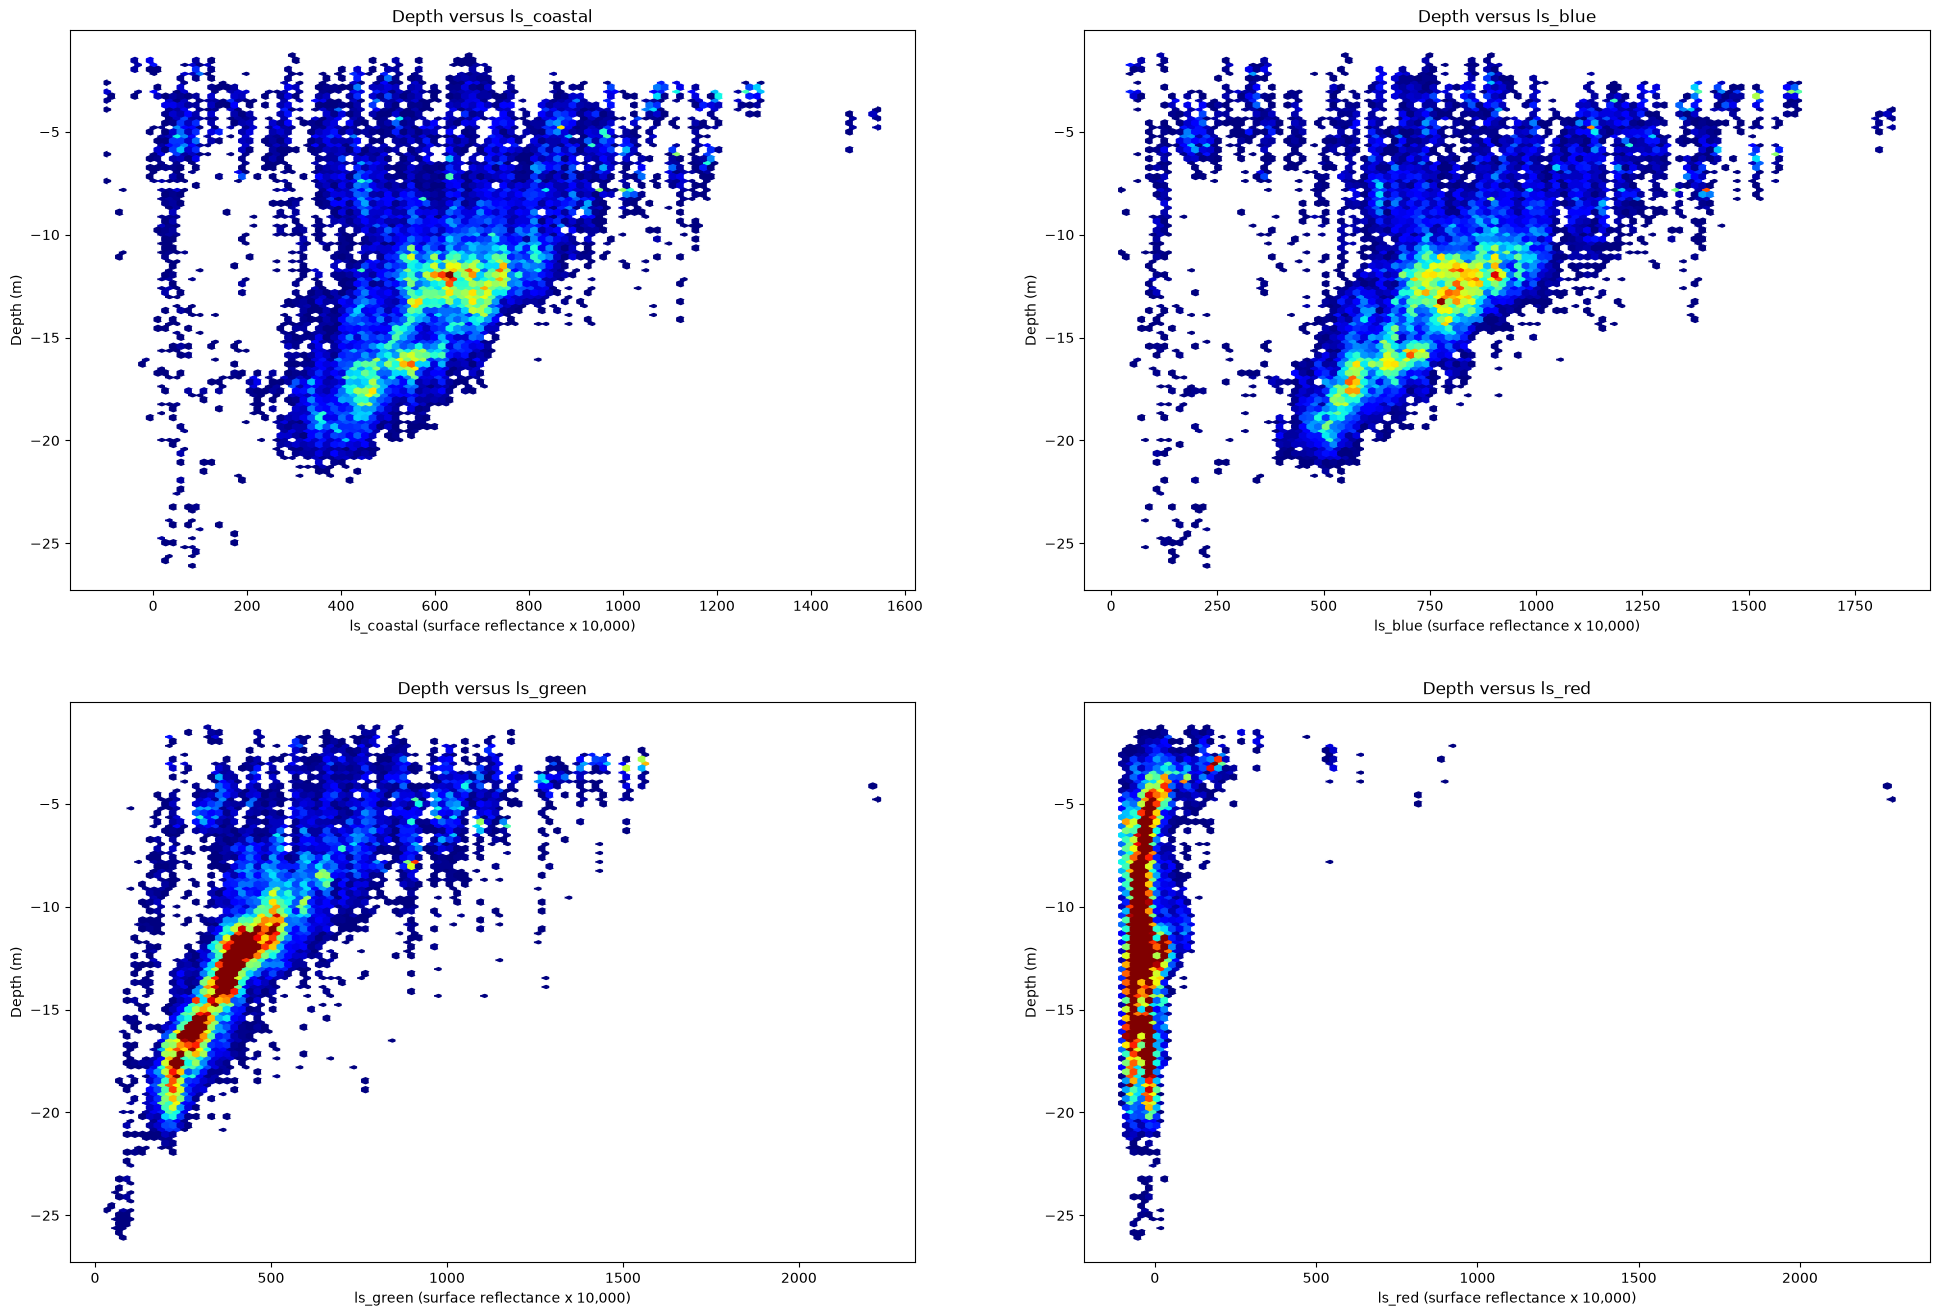

In [12]:
# Create the matplotlib figure
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(24, 16))

axs = [ax1, ax2, ax3, ax4]

cmap = plt.get_cmap("jet").copy()
cmap.set_under(color="white")
c_norm = mcolors.Normalize(vmin=1)

for i, ax in enumerate(axs):
    ax.hexbin(x[ind_vars[i]], y, gridsize=100, cmap=cmap, norm=c_norm)
    ax.title.set_text("Depth versus {}".format(ind_vars[i]))
    ax.set_xlabel(f"{ind_vars[i]} (surface reflectance x 10,000)")
    ax.set_ylabel("Depth (m)")

## 8.1 So what do these plots show?

In the first instance the most obvious thing is that the red reflectance doesn't seem to have a strong correspondence with depth, with the same reflectance values being at a wide variety of depths. We probably want to exclude that from our regression. While there is a lot of scatter the others seem to have some correspondence so we will keep those within our analysis. However, let's first look at the feature importance using the random forests model.

# 9. Fit a Random Forests Regression

For this analysis we are going to jump a few steps to get a result so we will not test and compare different regression algorithms or look to optimise the parameters (see section 5, `05_regression`, for that). The `random_state` is set so the results are repeatable.

In [13]:
skregrs_obj = RandomForestRegressor(n_jobs=-1, random_state=42)

skregrs_obj.fit(x, y)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

# 10. Feature Importance

For some algorithms (e.g., Random Forests) scikit-learn allows us to get access to the feature importance information. Let's have a look at that. `plot_feature_importance_bars` plots the importances as horizontal bars (the most important at the top), with the standard deviations of the permutation importances as error bars.

In [14]:
# Get the Feature Importances from the forest
importances = skregrs_obj.feature_importances_

# However, it is better to get a set of importances through a permutation analysis:
feat_impt_rslts = permutation_importance(
    skregrs_obj, x, y, n_repeats=10, random_state=42, n_jobs=2
)

In [15]:
for feat, impt, impt_std in zip(
    ind_vars, feat_impt_rslts.importances_mean, feat_impt_rslts.importances_std
):
    print(f"{feat}: {impt} ({impt_std})")

ls_coastal: 0.14417304766525746 (0.0020150041157599107)
ls_blue: 0.19718312895815468 (0.0022509679857374626)
ls_green: 1.8410382964071441 (0.009444857114321735)
ls_red: 0.09332231836582798 (0.0016018693794695388)


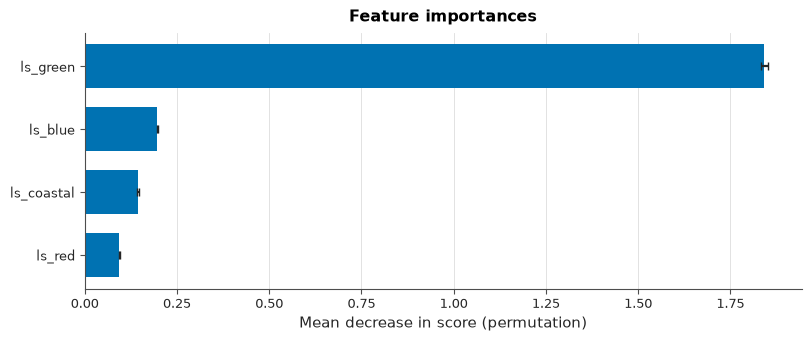

In [16]:
fig, ax = rsgispy.tools.plotting.plot_feature_importance_bars(
    ind_vars,
    feat_impt_rslts.importances_mean,
    errors=feat_impt_rslts.importances_std,
    title="Feature importances",
    xlabel="Mean decrease in score (permutation)",
)

## What can we see from the information above?

Well the first thing is that, as we thought, the red reflectance is contributing least to the model, so we should probably remove it. We might also remove the coastal band as well. Let's try removing the red. You can try running the analysis again removing the coastal variable. You would probably want to run that through to the end of the analysis to see what the effect would be on the final result of the analysis.

# 11. Redefine the Independent Variables

In [17]:
ind_vars = ["ls_coastal", "ls_blue", "ls_green"]
print("Independent Variables: ", ind_vars)

x = gdf[ind_vars]
x.shape

Independent Variables:  ['ls_coastal', 'ls_blue', 'ls_green']


(29067, 3)

In [18]:
# Create a new regression object
skregrs_obj = RandomForestRegressor(n_jobs=-1, random_state=42)
skregrs_obj.fit(x, y)

# Calculate the feature importances
feat_impt_rslts = permutation_importance(
    skregrs_obj, x, y, n_repeats=10, random_state=42, n_jobs=2
)

# Print the importances.
for feat, impt, impt_std in zip(
    ind_vars, feat_impt_rslts.importances_mean, feat_impt_rslts.importances_std
):
    print(f"{feat}: {impt} ({impt_std})")

ls_coastal: 0.175339325152144 (0.002023764866999984)
ls_blue: 0.26535977519224707 (0.0020094553544895985)
ls_green: 1.9650885706868633 (0.010839546636417546)


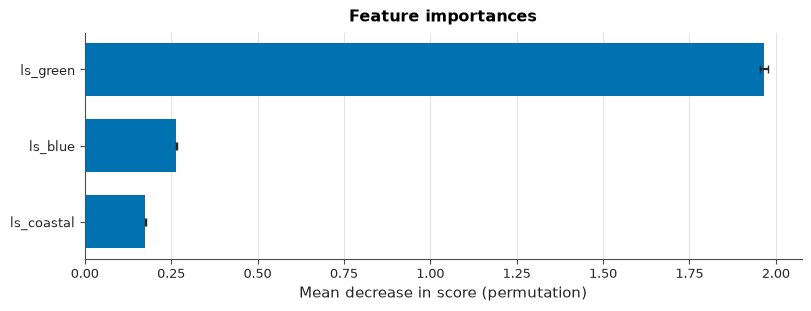

In [19]:
fig, ax = rsgispy.tools.plotting.plot_feature_importance_bars(
    ind_vars,
    feat_impt_rslts.importances_mean,
    errors=feat_impt_rslts.importances_std,
    title="Feature importances",
    xlabel="Mean decrease in score (permutation)",
)

# 12. Fit Final Model

The fitted model is saved with `rsgispy.regression.regsklearn.save_sklearn_regressor` (a compressed joblib file) so it can be reloaded later with `load_sklearn_regressor`.

In [20]:
# Create a new regression object
skregrs_obj = RandomForestRegressor(n_jobs=-1, random_state=42)
skregrs_obj.fit(x, y)

# Output model file
output_mdl_file = os.path.join(out_dir, "Bathy_RT_Depth_Model.joblib")

# Save regression model to disk:
print("Saving regression model...")
rsgispy.regression.regsklearn.save_sklearn_regressor(skregrs_obj, output_mdl_file)
print("Saved regression model.")

Saving regression model...
Saved regression model.


# 13. Define the Valid Area to Apply the Model to

Before applying the model we need to define the area for which the model should be applied. For this analysis that will be over the areas of water so we need to mask the land area. You have been supplied a vector layer of the land area so let's use that to create a mask.

The water mask is a thematic image so, after creating it, we name its class and give it a colour with `set_thematic_classes`, which also marks the image as thematic and calculates its statistics.

> **RSGISLib users:** rsgispy does not use raster attribute tables, so `rastergis.pop_rat_img_stats` (and setting the class names and colours in the attribute table) is replaced by `set_thematic_classes`.

In [21]:
land_area_img = os.path.join(out_dir, "bermuda_land_area.tif")
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    land_area_vec_file,
    land_area_vec_lyr,
    landsat_comp_img,
    output_img=land_area_img,
    burn_val=1,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)

water_area_img = os.path.join(out_dir, "bermuda_water_area.tif")
rsgispy.imagecalc.maths.image_math(
    land_area_img,
    water_area_img,
    "b1==1?0:1",
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)
rsgispy.imageutils.colourtable.set_thematic_classes(
    water_area_img, {1: ("Water", "#1E88E5")}
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

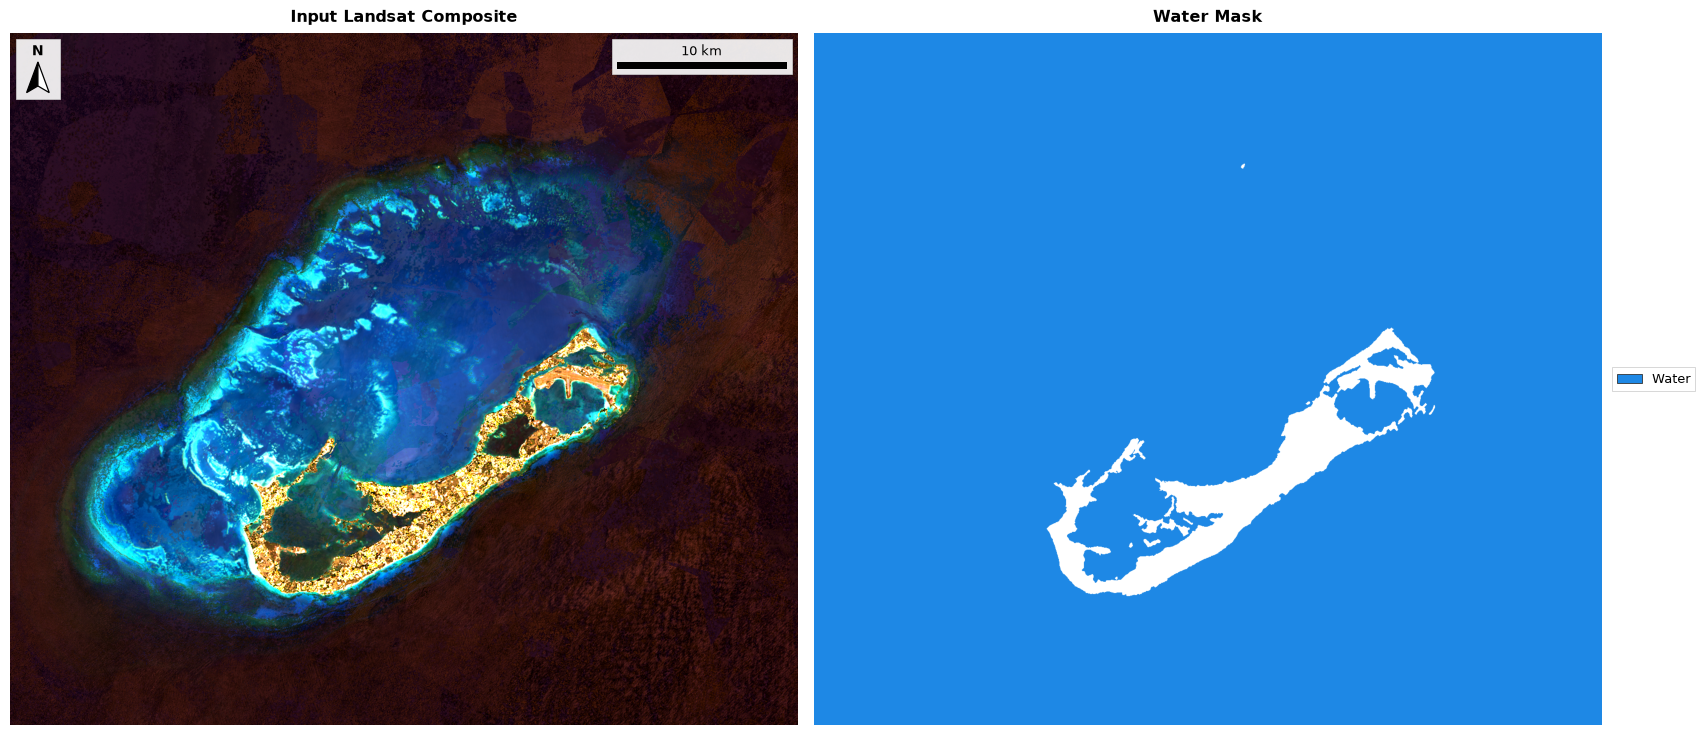

In [22]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb",
            landsat_comp_img,
            bands=[4, 3, 2],
            title="Input Landsat Composite",
            map_kw={"no_data_val": -9999},
        ),
        map_layout.MapPanel("thematic", water_area_img, title="Water Mask"),
    ],
    figsize=(16, 7.5),
)

# 14. Apply the Model to the Landsat Imagery

`apply_sklearn_regressor` applies the model block by block to the pixels where the mask image (`water_area_img`) is 1. The image bands are described with an `ImageBandInfo` object; the `band_names` must match the names of the columns the model was trained on. Pixels outside the mask, or with no data in the composite, are given the output no data value (0 here; all the valid depths are negative).

> **RSGISLib users:** this replaces `regresssklearn.apply_regress_sklearn_mdl`.

In [23]:
bathy_depths_img = os.path.join(out_dir, "bermuda_bathy_landsat_comp.tif")
img_band_info = [
    ImageBandInfo(
        landsat_comp_img, name="landsat", bands=[1, 2, 3], band_names=ind_vars
    )
]
rsgispy.regression.regsklearn.apply_sklearn_regressor(
    None,
    skregrs_obj,
    water_area_img,
    1,
    bathy_depths_img,
    img_band_info=img_band_info,
    target_cols="Depth",
    gdalformat="GTIFF",
    out_no_data_val=0.0,
    calc_stats=True,
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

# 15. Visualise the Result

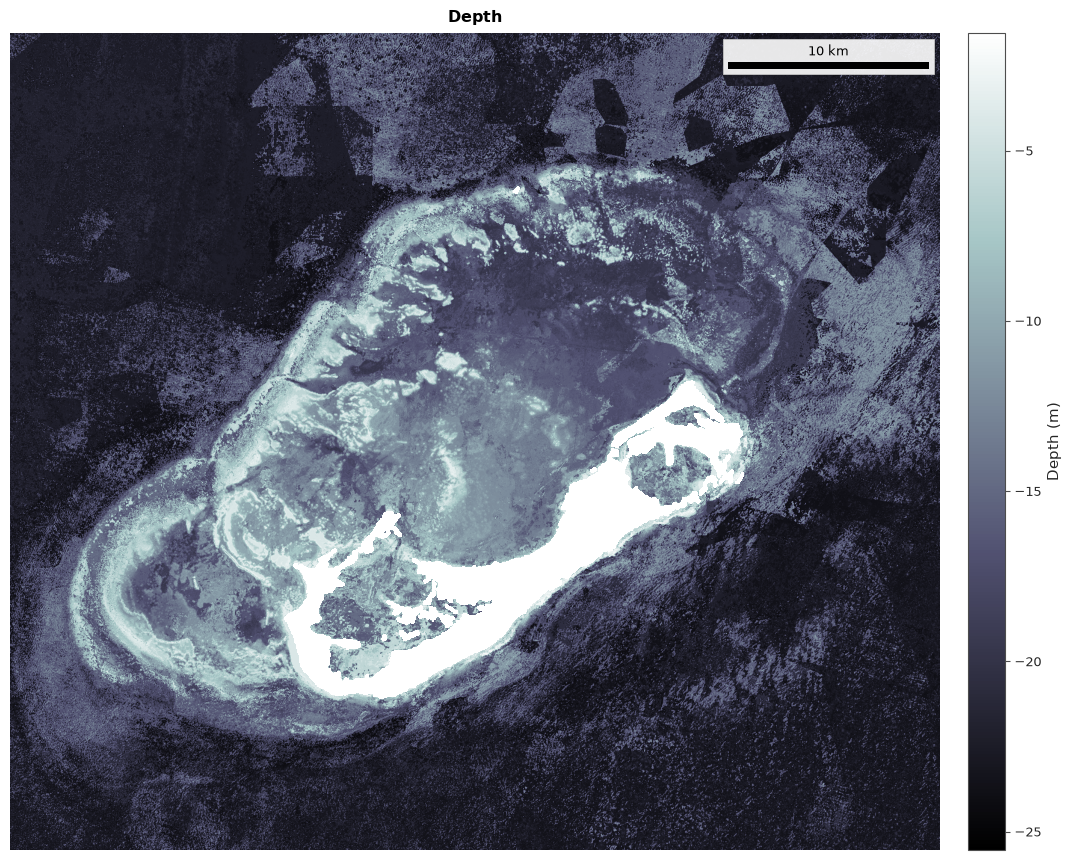

In [24]:
fig, ax = plt.subplots(figsize=(12, 12))
im = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax,
    bathy_depths_img,
    img_band=1,
    title_str="Depth",
    show_scale_bar=True,
    show_map_axis=False,
    cmap_name="bone",
    norm_img_vals=True,
    show_colour_bar=True,
    cbar_label="Depth (m)",
)

# 16. Assess the Quality of the Result

## 16.1 Extract the Predicted Depths at the Test Points

In [25]:
# Extract the predicted depth at the test points
rsgispy.zonalstats.point.ext_point_band_values_file(
    is2_test_vec_file,
    is2_test_vec_lyr,
    bathy_depths_img,
    img_band=1,
    min_thres=-50,
    max_thres=-0.0001,
    out_no_data_val=9999,
    out_field="ls_comp_depth",
)

  0%|          | 0/7405 [00:00<?, ?it/s]

## 16.2 Read Depth Values

In [26]:
# Open the GPKG file as a geopandas data frame - the gdf variable.
gdf = geopandas.read_file(is2_test_vec_file, layer=is2_test_vec_lyr)

print("All Columns: ", list(gdf.columns))

vld_gpdf = gdf.drop(gdf[gdf["ls_comp_depth"] == 9999].index)

print("There were {} rows which reduced to {}".format(len(gdf), len(vld_gpdf)))

All Columns:  ['field_1', 'Longitude', 'Latitude', 'PhotonHeig', 'Depth', 'LandConfid', 'ls_comp_depth', 'geometry']
There were 7405 rows which reduced to 7283


## 16.3 Plot Reference versus Predicted

`plot_pred_vs_obs` plots the predicted against the reference (observed) depths, with the 1:1 line, a fitted (trend) line and the main accuracy statistics.

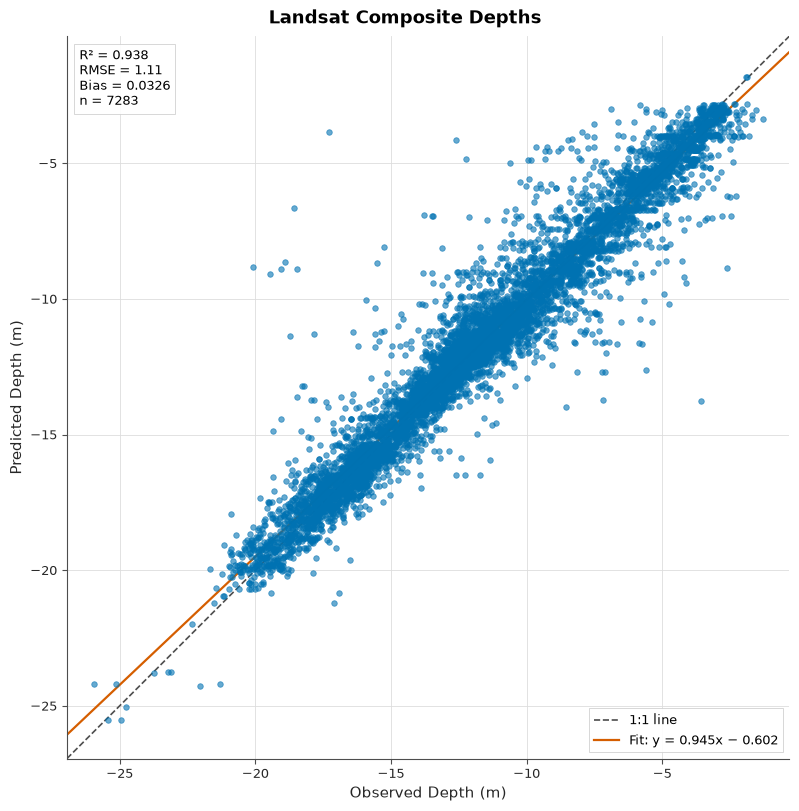

In [27]:
fig, axs = rsgispy.regression.regmetrics.plot_pred_vs_obs(
    vld_gpdf,
    ref_col="Depth",
    pred_col="ls_comp_depth",
    target_names=["Depth (m)"],
    title="Landsat Composite Depths",
    figsize=(8, 8),
)

## 16.4 Calculate Quality Statistics

`calc_reg_metrics` calculates the r2, RMSE, mean absolute error (MAE), bias, explained variance, Pearson correlation, mean squared error (MSE), and the normalised RMSE and bias (`nrmse`, the RMSE as a percentage of the mean reference depth; `nrmse_range`, as a percentage of the range of the reference depths; and `nbias`).

> **RSGISLib users:** this replaces `regression.get_regression_stats`.

In [28]:
reg_stats = rsgispy.regression.regmetrics.calc_reg_metrics(
    vld_gpdf,
    ref_col="Depth",
    pred_col="ls_comp_depth",
    out_json_file=os.path.join(out_dir, "bermuda_bathy_landsat_comp_metrics.json"),
)
reg_stats

{'r2': 0.9382842302507683,
 'rmse': 1.1094443639696243,
 'mae': 0.7058064484965342,
 'bias': 0.03255912422121676,
 'explained_variance': 0.9383373835862896,
 'pearson_r': 0.9687024804175227,
 'mse': 1.2308667967439642,
 'nrmse': -9.614345489348725,
 'nrmse_range': 4.498061014293686,
 'nbias': -0.28215445430120806,
 'n_samples': 7283}

### What can you see from these statistics and the plot above?

The first observation would be that the result looks pretty good. The results are scattered about the 1:1 line which is a good sign and this is shown as the r2 is 0.94. The RMSE is 1.11 m and the normalised RMSE is -9.6 % (negative because the depths are negative). Therefore, we can conclude the average error is about 1.1 metres which is about 10 % of the values. (Your numbers may differ slightly from those discussed here if you change the composite, the random seeds or the train/test split.)

## 16.5 Plot Residuals

`plot_residuals` plots the residuals (predicted - observed) against the predicted values and, beside it, a histogram of the residuals with a fitted normal distribution.

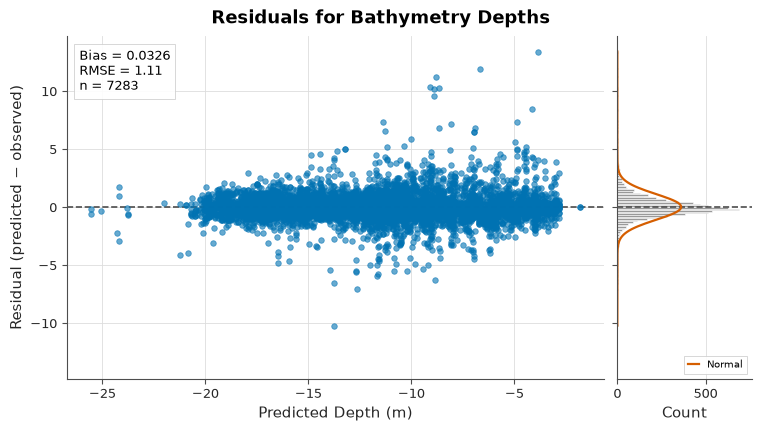

In [29]:
fig, axs = rsgispy.regression.regmetrics.plot_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="ls_comp_depth",
    target_names=["Depth (m)"],
    title="Residuals for Bathymetry Depths",
)

The residuals plot shows that there isn't a particular bias within the residuals so that looks good. There may be a hint of something towards the ends though.

## 16.6 Investigating the normality of residuals

A quantile-quantile (QQ) plot compares the distribution of the residuals with a normal distribution; if the residuals are normal the points follow the straight line. `plot_qq_residuals` calculates the residuals and draws the QQ plot; `rsgispy.tools.plotting.plot_qq` draws one for any array of values. By default the plot also gives the Shapiro-Wilk normality test, but its p-value is not reliable for more than 5000 values (and with this many values any small departure from normality is significant), so it is turned off here (`show_shapiro=False`).

> **RSGISLib users:** this replaces `tools.plotting.quantile_plot`.

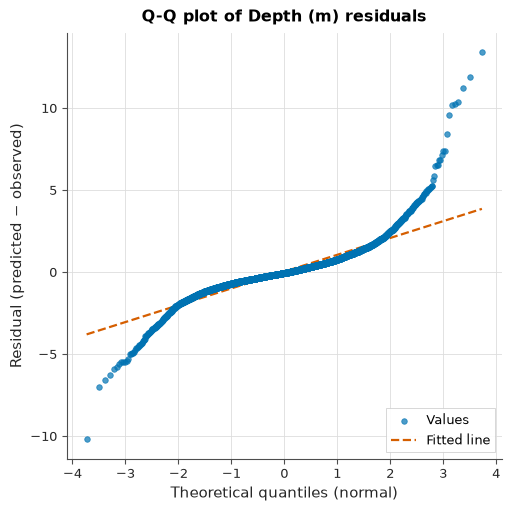

In [30]:
fig, axs = rsgispy.regression.regmetrics.plot_qq_residuals(
    vld_gpdf,
    ref_col="Depth",
    pred_col="ls_comp_depth",
    target_names=["Depth (m)"],
    show_shapiro=False,
)

Looking at the QQ plot we can see that the main centre of the distribution (± 2 quantiles) is normal but there are some biases at the ends of the distribution, i.e., the largest errors are larger than a normal distribution would give. This is likely to be because there are fewer samples at the ends of the distribution (the deepest and shallowest points).

# 17. Finalising the Bathymetric Depth Layer

The depth samples from ICESat-2 were focused on the lagoon area of Bermuda which is up to about 25 m in depth. Therefore, the areas outside the lagoon should be masked from the datasets so the pixel values are all valid. The `bermuda_valid_water_mask` layer outlines the areas to be removed.

In [31]:
ocean_area_img = os.path.join(out_dir, "bermuda_ocean_area.tif")
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    ocean_area_vec_file,
    ocean_area_vec_lyr,
    landsat_comp_img,
    output_img=ocean_area_img,
    burn_val=1,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

In [32]:
bathy_depths_fnl_img = os.path.join(out_dir, "bermuda_bathy_landsat_comp_fnl.tif")
# Pixels where the ocean mask is 1 are set to 0 (no data)
rsgispy.imageutils.masking.mask_img(
    bathy_depths_img,
    ocean_area_img,
    bathy_depths_fnl_img,
    out_value=0,
    mask_value=1,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
    no_data_val=0,
    calc_stats=True,
)

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

  0%|          | 0/42 [00:00<?, ?it/s]

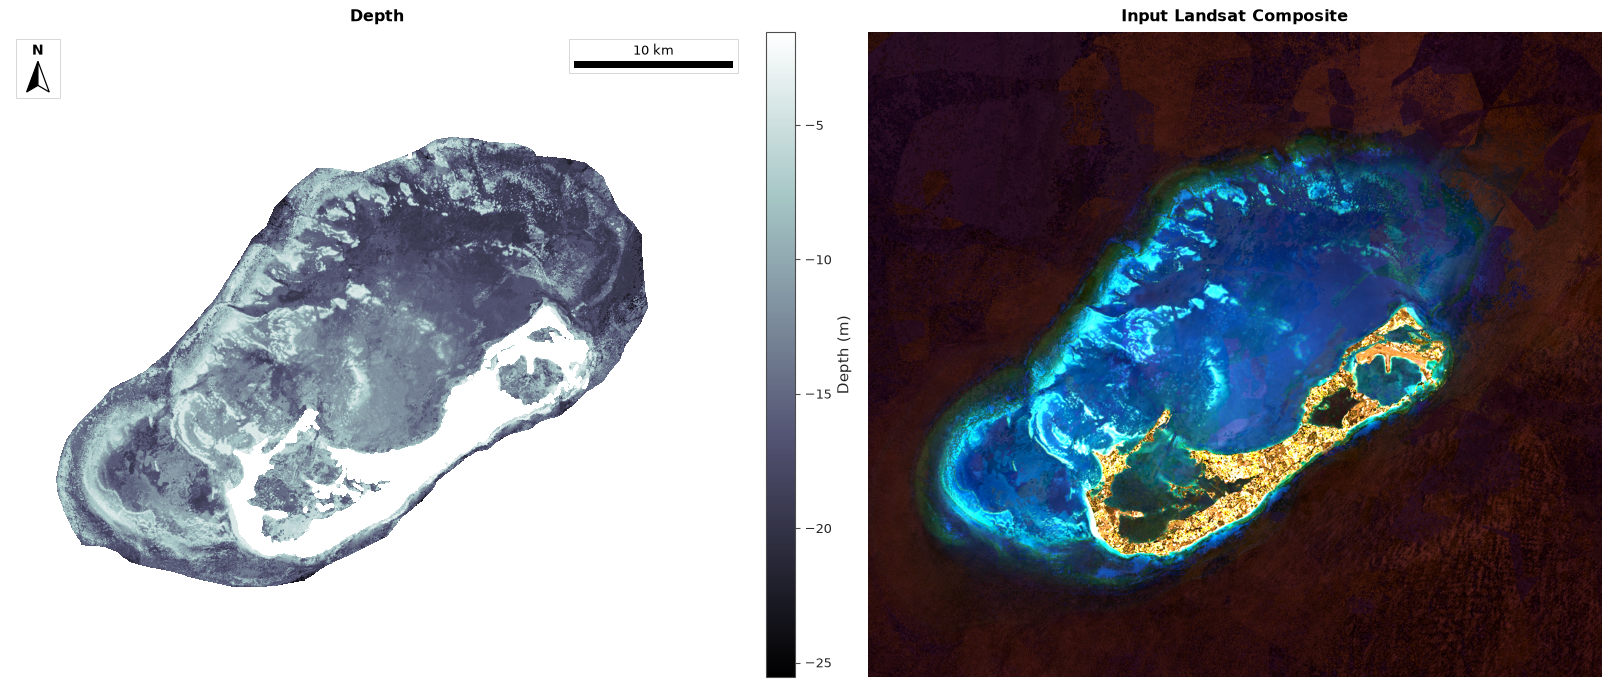

In [33]:
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "cmap",
            bathy_depths_fnl_img,
            cmap_name="bone",
            title="Depth",
            show_colour_bar=True,
            cbar_label="Depth (m)",
        ),
        map_layout.MapPanel(
            "rgb",
            landsat_comp_img,
            bands=[4, 3, 2],
            title="Input Landsat Composite",
            map_kw={"no_data_val": -9999},
        ),
    ],
    figsize=(16, 7.5),
)